# Assignment 2

This project is designed to mirror a real-world analysis workflow, guiding you from the initial steps of data wrangling to the more advanced concepts of dimensionality reduction.

You will practice a range of essential data science skills, including:

- Data Cleaning: Handling missing values and ensuring data is in the correct format for analysis.

- Exploratory Data Analysis (EDA): Using visualizations to explore trends and patterns in the data.

- Correlation Analysis: Quantifying the relationships between different sales regions.

- Principal Component Analysis (PCA): Applying a powerful machine learning technique to understand data structure.

By the end of this project, you will have not only practiced your coding skills but also sharpened your ability to interpret results and communicate your findings effectively.

## Submission Requirements

To receive full credit, your submission must be a single, fully executed Jupyter Notebook file (.ipynb). This notebook should serve as a complete report that seamlessly integrates your work and thoughts. Please ensure your submission includes the following for every task:

- All Code: Every line of code you write to complete the tasks must be present and executable in the notebook.

- All Results: The output of each code cell (e.g., tables, plots, print statements) must be visible directly below the cell that generated it. Do not clear the outputs before submitting.

- Analysis and Comments: For each task that requires it, provide clear and concise written answers to the analytical questions. This is a critical part of the assignment and should be written in the designated markdown cells.

- Explanatory Report: Your notebook should be written as a report that explains your process. Use markdown cells to:

  - Explain the logic and purpose of your code.

  - Interpret the results of your analysis (e.g., explain what a graph is showing).

  - Justify the decisions you made during the analysis.

Your final notebook should be a polished document that another analyst could read to understand your workflow, methods, and conclusions. Good luck!

### First, let's import our libraries and load the dataset.

In [1]:
!pip install -q scikit-learn # Installs the scikit-learn machine learning library.
import pandas as pd # Imports pandas for data handling and working with DataFrames.
import seaborn as sns # Imports seaborn for creating attractive statistical visualizations.
import matplotlib.pyplot as plt # Imports matplotlib's pyplot for creating and customizing plots.
import numpy as np # Imports numpy for numerical operations and handling arrays.


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: C:\Users\dennn\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip
ERROR: Invalid requirement: '#': Expected package name at the start of dependency specifier
    #
    ^


---

### Task 1: Load and Inspect the Data

1. Load the `vgsales.csv` file into a pandas DataFrame.
2. Display the basic information of the DataFrame using `.info()`.
3. Print the number of missing values in each column.

#### Explanatory report for Task 1

I loaded the video game sales dataset with `pd.read_csv("vgsales.csv")`.

I used `df.info()` to check row count, column names, data types, and how many non-null values each column has.

I printed `df.isna().sum()` to count missing values per column. The output showed missing data only in Year and Publisher.

In [2]:
# Write your code here:
df = pd.read_csv("vgsales.csv")
df.info()

print(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  str    
 2   Platform      16598 non-null  str    
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  str    
 5   Publisher     16540 non-null  str    
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), str(4)
memory usage: 1.4 MB
Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64


---

### Task 2: Data Cleaning

1. **Handle Missing Values**: 
   - Fill the missing values in the `Year` column with the **median** year.
   - Fill the missing values in the `Publisher` column with the string 'Unknown'.
2. **Correct Data Types**: Convert the `Year` column to an `integer` type.
3. **Drop Remaining Nulls**: Drop any other rows that still contain null values.
4. **Verify**: Print the info of the DataFrame again to confirm your changes.

#### Explanatory report for Task 2

**Missing values:** I filled missing Year values with the column median. Missing Publisher values became the label `'Unknown'`.

**Data types:** After imputation, I converted Year to `int` because release year should be a whole number for analysis and plotting.

**Remaining nulls:** I called `df.dropna()` so any row that still had a null in any column would be removed.

**Verification:** Running `df.info()` again confirmed all 11 columns have 16,598 non-null entries, Year is `int64`.

In [3]:
# Write your code here:
df["Year"] = df["Year"].fillna(df["Year"].median()) # filling nans with median of Year
df["Publisher"] = df["Publisher"].fillna("Unknown") # filling nans with string Unknown

df["Year"] = df["Year"].astype(int) # changing year col dtype to int

df = df.dropna()

df.info()
# print(df.isna().sum()) # making sure there's 0 null values

df

<class 'pandas.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  str    
 2   Platform      16598 non-null  str    
 3   Year          16598 non-null  int64  
 4   Genre         16598 non-null  str    
 5   Publisher     16598 non-null  str    
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(5), int64(2), str(4)
memory usage: 1.4 MB


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
...,...,...,...,...,...,...,...,...,...,...,...
16593,16596,Woody Woodpecker in Crazy Castle 5,GBA,2002,Platform,Kemco,0.01,0.00,0.00,0.00,0.01
16594,16597,Men in Black II: Alien Escape,GC,2003,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01
16595,16598,SCORE International Baja 1000: The Official Game,PS2,2008,Racing,Activision,0.00,0.00,0.00,0.00,0.01
16596,16599,Know How 2,DS,2010,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01


---

### Task 3: Exploratory Analysis - A Look at Action Game Sales

Your goal is to understand the typical sales performance of an 'Action' game.

1.  **Select the Genre**: Create a new DataFrame that only contains games from the **'Action'** genre.
2.  **Filter for Readability**: From your 'Action' games DataFrame, create a second DataFrame that only includes games that sold **less than 5 million copies** globally.
3.  **Create a Histogram**: Make a histogram of the `Global_Sales` for the filtered 'Action' games. Use 20 bins for good detail.
4.  **Analyze**: Answer the questions in the markdown cell below.

**Hint:** Before you write your own code, an example of how to draw histogram plots is given below for your reference.


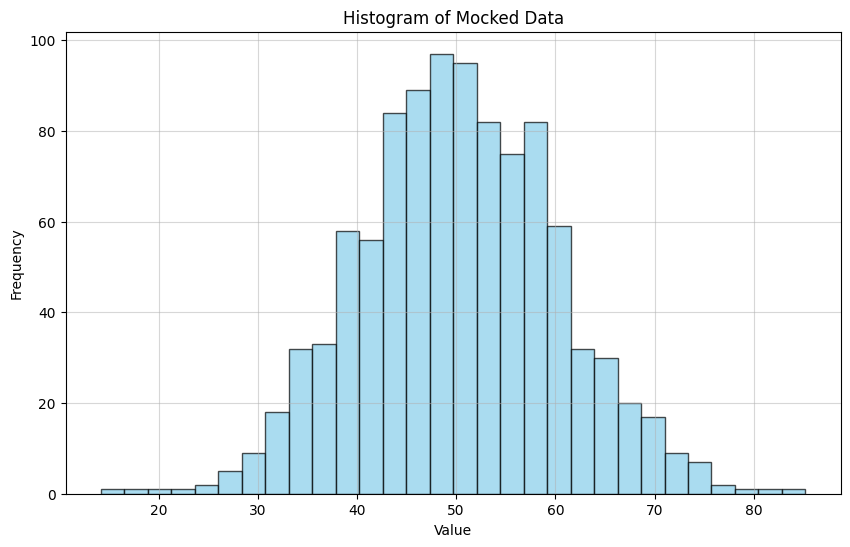

In [4]:
# --- 1. Mock Data Generation ---
# Create 1,000 random numbers with a mean of 50 and a standard deviation of 10
# This will create data that clusters around the number 50.
mean = 50
std_dev = 10
data_points = 1000
mock_data = np.random.normal(mean, std_dev, data_points)

# --- 2. Plotting with plt.hist() ---
# Set the figure size
plt.figure(figsize=(10, 6))

# Create the histogram with 30 bins for good detail
plt.hist(mock_data, bins=30, alpha=0.7, color='skyblue', edgecolor='black')

# Add a title and labels for clarity
plt.title('Histogram of Mocked Data')
plt.xlabel('Value')
plt.ylabel('Frequency')

# Add a grid for easier reading
plt.grid(True, alpha=0.5)

# Display the plot
plt.show()

#### Explanatory report for Task 3

**Filtering:** I built `df_action` with `df["Genre"] == "Action"` to restrict the analysis to one genre. I then created `df_action_5_mil_less` with `Global_Sales < 5` so the histogram emphasizes typical Action titles.

**Visualization:** I used `plt.hist(..., bins=20)` on the filtered Global_Sales column with axis labels and a title so the chart reads as how many Action games (under 5M copies) fall in each sales bin.

**What the plot shows:** Most games pile up in the lowest sales bins (roughly 0–1M), with counts dropping quickly toward 5M. That right-skew means many low-selling Action games and relatively few high sellers in this filtered view.

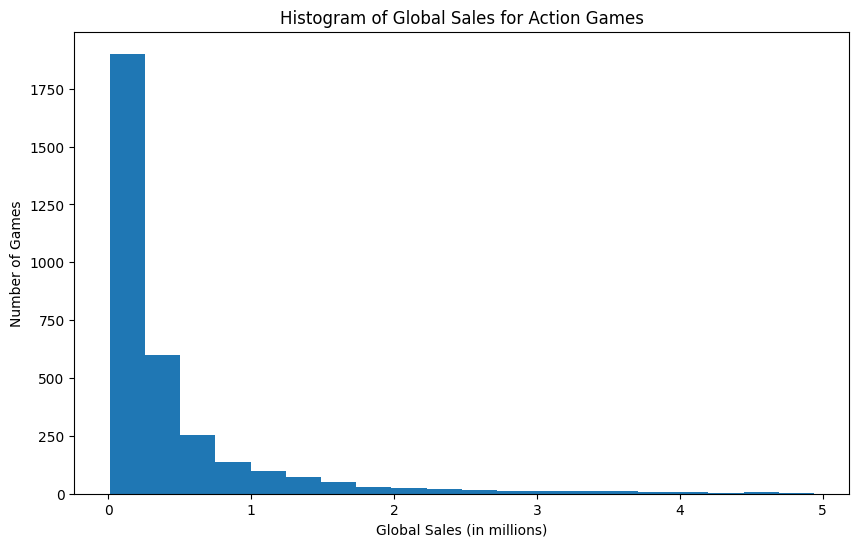

In [5]:
# Write your code here for the histogram using plt.hist()
df_action = df[df["Genre"] == "Action"] # filter for only action genre

df_action_5_mil_less = df_action[df_action["Global_Sales"] < 5] # using action only df to filter for games that have less than 5 mil global copies

plt.figure(figsize=(10,6)) # set fig size

# plt.hist(df_action['Global_Sales'], bins=20, edgecolor='black') # plot
plt.hist(df_action_5_mil_less['Global_Sales'], bins=20) # plot
plt.title("Histogram of Global Sales for Action Games")
plt.xlabel('Global Sales (in millions)')
plt.ylabel('Number of Games')
plt.show()

#### **Analysis for Task 3**

1.  **Looking at your histogram, what is the most common sales range for an Action game? (i.e., Where is the tallest bar?)**

2.  **Does the 'Action' genre have a lot of low-selling games? How can you tell from the graph?**

**Double click to write your analysis here..**

1. The most common sales range for action games is roughly 0 to about 1 million Global Sales, reaching almost 3000 sales. This is the tallest bar in the histogram
2. Yes the 'Action' genre does have a lot of low-selling games. I can tell from this graph because the bars are very right skewing, and this is where Global Sales is about 1 million sales. The bars on the right side are barely seen at all, and these are for games with 3-5 million global sales.

### Task 4: Correlation Analysis

#### What is a Correlation Matrix?

Before the code, here's a simple explanation: A correlation matrix is consist of pearson correlation score between corresponding entries. 

For example, the (i, j) entry of the matrix, is the pearson correlation score between feature i and feature j.

A heatmap helps us see these relationships instantly by using color. 🎨

Now your todos in task 4 is:
1. Select the sales columns: `NA_Sales`, `EU_Sales`, `JP_Sales`, `Other_Sales`, and `Global_Sales`.
2. Calculate the Pearson correlation matrix for these columns.
3. Visualize the correlation matrix using a **heatmap**.
4. Analyze the heatmap in the markdown cell below.

**Hint:** Before you write your own code, an example of how  plot heat map has been given for your reference.

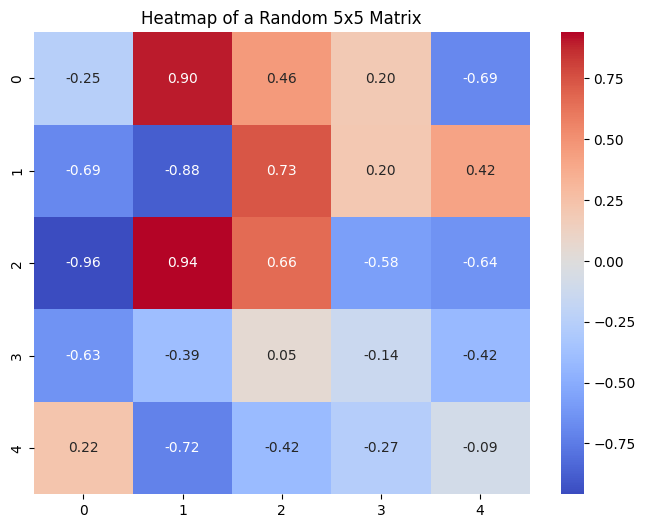

In [6]:
# --- 1. Create a Generic 5x5 Square Matrix with Random Data ---
# Use a seed for reproducibility so the random numbers are the same every time.
np.random.seed(42)

# Create a 5x5 matrix with random values between -1 and 1.
# This is just a placeholder to demonstrate the plotting function.
random_matrix = np.random.uniform(-1, 1, size=(5, 5))


# --- 2. Visualize the Matrix with a Heatmap ---
plt.figure(figsize=(8, 6))

# sns.heatmap() creates the visualization.
# - annot=True displays the numerical values in each cell.
# - cmap='coolwarm' is a color scheme where high values are warm (red) 
#   and low values are cool (blue).
# - fmt='.2f' formats the numbers to two decimal places.
sns.heatmap(random_matrix, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Heatmap of a Random 5x5 Matrix')
plt.show()

#### Explanatory report for Task 4

I selected only the five sales columns into `df_sales`.

I computed `df_sales.corr(method="pearson")` to quantify linear association between each pair of column.

I plotted the matrix with `sns.heatmap(..., annot=True, cmap='coolwarm', fmt='.2f')`.

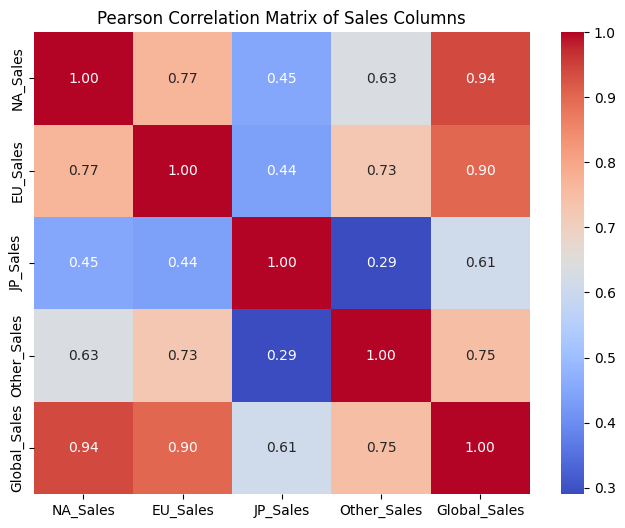

In [7]:
# Write your code here for the heatmap using sns.heatmap()
df_sales = df[['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']] # filter for sales cols

correlation_matrix = df_sales.corr(method="pearson") # pearson corrlation matrix of sales df

# corrlelation_matrix

plt.figure(figsize=(8,6)) # set fig size

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Pearson Correlation Matrix of Sales Columns")
plt.show()

#### **Analysis and Feature Selection Question:**

After creating your heatmap, answer the following in the markdown cell provided:

1.  **Analysis**: Which feature have the strongest positive correlation with `Global_Sales`? Is this what you would expect? Why?    
2.  **Feature Selection**: Imagine you are building a machine learning model to predict `Global_Sales`.   
If you had to remove two of the feature columns (`NA_Sales`, `EU_Sales`, `JP_Sales`, `Other_Sales`) to simplify your model, which two of them would you remove and why?     

**Double click to write your analysis here..**

1. NA_Sales has the strongest positive correlation with Global_Sales. This is somewhat expected because when we look at the data, NA_Sales typically contribute the most to Global Sales (NA_Sales are normally the largest value in the data compared to other sales).
2. If I had to remove 2 of the feature columns to simplify my ML model in predicting global sales, I would remove the 2 columns that have the smallest correlation to global sales. From the correlation matrix, this would be JP_Sales and Other_Sales, and this is simply because they have the weaker correlations with global sales compared to NA_Sales and EU_Sales

#### Explanatory report for Task 4 Feature Selection

For prediction, Global_Sales is the target, not an input feature. I took the Global_Sales column from the correlation matrix, dropped the self-correlation entry, and kept one correlation value per regional sales column.

I used `.nsmallest(2)` on those correlations to remove the two regions least linearly related to Global_Sales (JP_Sales and Other_Sales in the output). The remaining columns (NA_Sales, EU_Sales) are the pair I would keep as simpler predictors because they show stronger Pearson correlation with global totals in the heatmap.

In [8]:
# Write your code here for feature selection based on correlation..

'''
Drop Global sales from correlation matrix since it is the value we want to predict and no longer need it in feature selection
'''
correlation_matrix_updated = correlation_matrix['Global_Sales'].drop('Global_Sales')

# print(correlation_matrix['Global_Sales'])
# print(correlation_matrix_updated)

features_to_remove = correlation_matrix_updated.nsmallest(2).index # selects the indices of the 2 smallest correlation values in correlation_matrix_updated

selected_features = correlation_matrix_updated.drop(features_to_remove).index.tolist() # features we are keeping

print("Features removed:", features_to_remove.tolist())
print("Features selected:", selected_features)

Features removed: ['JP_Sales', 'Other_Sales']
Features selected: ['NA_Sales', 'EU_Sales']


---

### Task 5: A Deeper Dive into PCA - The Swiss Roll Challenge

In this final task, we will explore the capabilities and limitations of Principal Component Analysis (PCA). We'll use a special dataset called a "Swiss Roll" to see how PCA, a **linear** technique, handles complex, **non-linear** data.

#### **Getting Started: Visualizing Our Data**

Before we can analyze the data, we need to see what we're working with. The code cell below will:
1.  Generate the Swiss Roll dataset using the `make_swiss_roll` function.
2.  Create a **3D scatter plot** to reveal its true, underlying structure.

Run the cell to see what the data looks like.

*_(This code is provided for you as scaffolding; your graded task is in the section below.)_*

Displaying the original 3D structure of the Swiss Roll...


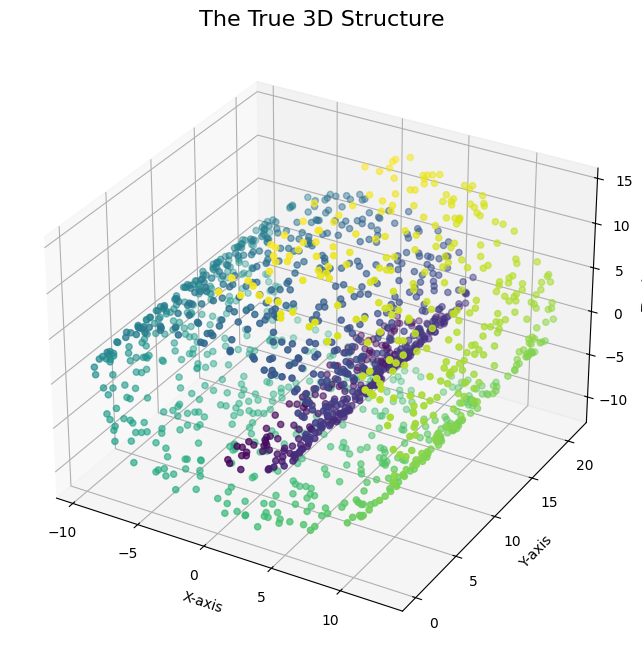

In [9]:
# --- Data Generation ---
# Generate the Swiss Roll dataset as specified in the task.
from sklearn.datasets import make_swiss_roll # Imports the function to create the Swiss Roll dataset.

X, color = make_swiss_roll(n_samples=1500, noise=0.1, random_state=42)

# --- Visualizing the 3D Data ---
print("Displaying the original 3D structure of the Swiss Roll...")
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=color, cmap=plt.cm.viridis)
ax.set_title(" The True 3D Structure", fontsize=16)
ax.set_xlabel('X-axis')
ax.set_ylabel('Y-axis')
ax.set_zlabel('Z-axis')
plt.show()

#### **Task 5.1: Observe the 3D Structure**

Now that you've seen the plot, your first task is to describe what you see.

**Your Instructions:**
* In a new markdown cell, answer the following question in 1-2 sentences:
    > **Observe**: What is the intrinsic shape of this data? Does it look like it could be "unrolled" into a simple 2D plane?


#### **Task 5.2: Apply PCA and Visualize the Result**

Next, let's see what happens when we ask PCA to reduce this 3D structure down to a 2D plane.

**Your Instructions:**
1.  Initialize `PCA` from `scikit-learn`, fit and transform the 3D Swiss Roll data (`X`) to get your new 2D data.
2.  Create a **2D scatter plot** of the result, coloring the points using the `color` variable.


#### **Task 5.3: The "Why" - Analysis and Comments**

The plot from Task 5.2 probably doesn't look like an "unrolled" sheet, explain why.

**Your Instructions:**
1.  Look at the "before" (3D plot) and "after" (2D PCA plot) visualizations side-by-side.
2.  In a new markdown cell, write a brief explanation (2-3 sentences) answering the following question:
    > *Why did PCA fail to "unroll" the Swiss Roll? Based on your results, what does this tell you about the kind of structures PCA is good at analyzing?*

#### Explanatory report for Task 5

I imported `PCA` from scikit-learn and set `n_components=2` to project the 3D Swiss roll coordinates X onto two principal components.

`pca.fit_transform(X)` learns the linear projection on the data and returns the 2D coordinates in `pca_for_X`.

I plotted the first vs. second component with `plt.scatter`, coloring points with the `color` array from `make_swiss_roll` so the rolled structure is still visible after reduction. The 2D view keeps a curved, rolled pattern rather than a flat sheet consistent with PCA being a linear method on nonlinear geometry.

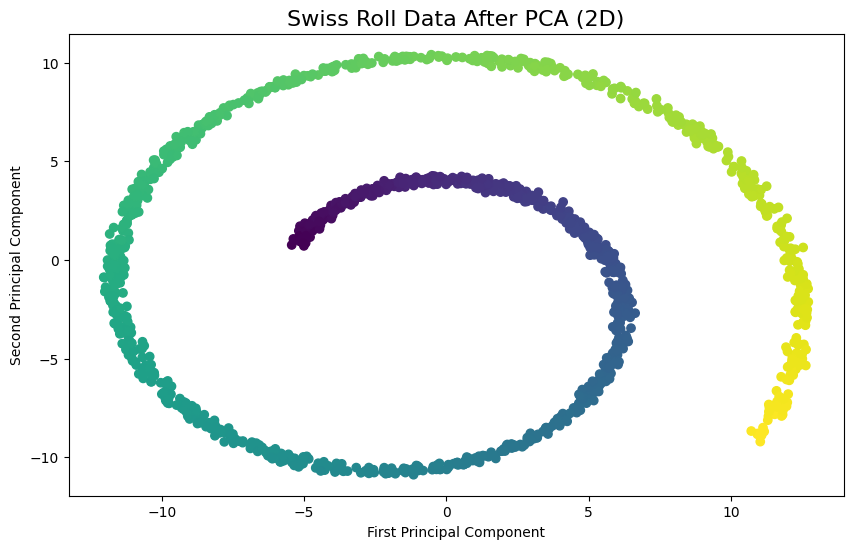

In [10]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2) # initialize pca to 2 principal components

pca_for_X = pca.fit_transform(X) # fit and transform data

plt.figure(figsize=(10,6)) # figure size

plt.scatter(pca_for_X[:, 0], pca_for_X[:, 1], c=color, cmap=plt.cm.viridis) # create scatter plot for the 2-D data

plt.title("Swiss Roll Data After PCA (2D)", fontsize=16)
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.show()


**Double click to write your analysis here..**

PCA failed to "unroll" the Swiss Roll because it only performs linear transformations, meaning it projects the data onto a flat plane without undoing the nonlinear curvature of the surface. As a result, the plot still looks like a rolled up view of the original 3D structure rather than a flat, unrolled sheet. This tells us that PCA is best suited for analyzing data with linear relationships and structures.

5.1: From my intuition, the shape of the data looks like a rolled shape with a weird curve by the teal points. Yes, this looks like it can be unrolled into a simple 2D plane.
<br>
5.3: The plot doesn't look like an unrolled sheet because PCA only performs linear transformations. Instead, the plot looks more like a forward facing, rolled up view of the original 3D surface. PCA projects the data onto a lower dimensional plane, but it cannot undo the nonlinear curvature of the surface to reveal a completely unrolled sheet.